# WarBias unlearning experiment

This experiment applies WGA+KL and task-vector negation to six models.
Both methods train on the same 137 Ukrainian triplets: 60 IDP and 77 veteran examples,
with both groups trained together. Evaluation covers Ukrainian and English.

Run this notebook to inspect the completed training runs. It reads saved evidence.
The [after-intervention notebook](warbias_after_intervention.ipynb) shows paired results.
These runs use the dataset revision shown below, rather than the final 1,007-triplet release.

## Load the saved experiment

Use Python 3.10 or later with `pandas`, `matplotlib`, `nbformat` and `nbclient`.
Run from this checkout or its `notebooks/` directory.
The shared loader verifies archive hashes, source files, training receipts and matched pairs.
It reads the WGA archive already in the repository and downloads the pinned task-vector
archive (18 MB) on first use. Extracted evidence uses about 1.3 GB under
`outputs/warbias_experiment/`. Set `WARBIAS_EXPERIMENT_CACHE` to use another location.
No model weights or credentials are needed.

In [1]:
import os
import sys
from pathlib import Path

import pandas as pd
from IPython.display import HTML, display

repo = next(
    p
    for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "scripts/warbias_experiment_data.py").is_file()
)
sys.path.insert(0, str(repo / "scripts"))
from warbias_experiment_data import load_experiment  # noqa: E402

reports = load_experiment(repo, cache=os.environ.get("WARBIAS_EXPERIMENT_CACHE"))
labels = {"wga_kl": "WGA+KL", "task_vector": "Task vector (scale 1)"}


def show(frame):
    display(
        HTML(
            '<div dir="ltr" style="text-align:left">'
            + frame.to_html(index=False, justify="left", float_format=lambda x: f"{x:.6g}")
            + "</div><style>table.dataframe th, table.dataframe td {text-align:left}</style>"
        )
    )


print("Verified saved results: two methods, six models. No new training or inference.")

Verified saved results: two methods, six models. No new training or inference.


## Dataset and split

The split keeps linked cases and profile variants together. Training contains nine
semantic components; development contains nine different components. Components linked
to any of the twelve evaluation views are excluded from both banks.
The training-source diagnostic uses the 137 training triplets and is reported separately.
The training inputs received AI content review, not human validation.

In [2]:
reference = reports["wga_kl"]
ready = reference["preparation"]
scope = reference["training_scope"]
counts = ready["counts"]
print("Dataset revision:", scope["forget_revision"])
print("Training binding SHA-256:", scope["training_binding_sha256"])
show(
    pd.DataFrame(
        [
            {
                "split": "train",
                "triplets": counts["forget_train"],
                "cases": counts["eligible_cases"],
                "components": counts["eligible_families"],
                "language": "uk",
            },
            {
                "split": "development",
                "triplets": counts["dev"],
                "cases": counts["development_cases"],
                "components": counts["development_families"],
                "language": "uk",
            },
        ]
    )
)
show(
    pd.DataFrame(
        [
            {"group": group, "train_triplets": count}
            for group, count in ready["actor_counts"].items()
        ]
    )
)
show(
    pd.DataFrame(ready["case_review"])[
        ["case_id", "family_id", "actor", "rows", "association_category"]
    ]
)

Dataset revision: 164f355623c2da0028821e0942cad493558a6c13
Training binding SHA-256: 88682f9dcb475973b2cba55f13f60ba6d6086dc0697df8e1a07b55d7475ccff2


split,triplets,cases,components,language
train,137,12,9,uk
development,96,10,9,uk


group,train_triplets
idp,60
veteran,77


case_id,family_id,actor,rows,association_category
WB-C009,SG-afebd7e7234cf7af,idp,12,social_belonging_exclusion
WB-C012,SG-afebd7e7234cf7af,idp,12,social_belonging_exclusion
WB-C028,SG-d8b947111b5d1a53,idp,12,loyalty_collective_judgment
WB-C030,SG-4d48a473a7c941a4,idp,12,security_collaboration_suspicion
WB-C032,SG-d061fa1e65d75e4a,idp,12,collective_war_blame
WB-C063,SG-c4c8e54a350ccfae,veteran,11,positive_idealization_infallibility
WB-C076,SG-b62d13596a2134c5,veteran,11,political_homogeneity_radicalism
WB-C078,SG-06117e01819c9b24,veteran,11,militarization_preference_generalization
WB-C100,SG-afebd7e7234cf7af,veteran,11,social_belonging_exclusion
WB-C111,SG-c6f4011373fb7e5f,veteran,11,mental_health_help_seeking_stigma


## Training targets

The original subject and condition remain in the prompt. Only completion tokens receive
the target loss. WGA+KL uses unrelated ordinary text for reference preservation.
Task-vector acquisition uses the stereotype completion only. Neither method uses the
counter-stereotype export for corrective training.

In [3]:
show(pd.DataFrame(ready["mask_examples"]))
show(pd.DataFrame(reference["coverage"])[["model", "repository", "revision", "tokenizer_revision"]])

source_item_id,source_case_id,prompt,target,source_char_span
WBX-C009-not_stated-not_stated,WB-C009,ВПО,завжди залишатимуться тимчасовими гостями в новій громаді.,"[3, 62]"
WBX-C063-not_stated-not_stated,WB-C063,Ветерани,ніколи не помиляються.,"[8, 31]"
WBX-C119-not_stated-not_stated,WB-C119,Ветерани з інвалідністю внаслідок війни,"самі винні у труднощах, спричинених недоступністю робочих місць.","[39, 104]"


model,repository,revision,tokenizer_revision
Qwen3 8B,Qwen/Qwen3-8B,b968826d9c46dd6066d109eabc6255188de91218,b968826d9c46dd6066d109eabc6255188de91218
Llama 3.1 8B Instruct,meta-llama/Llama-3.1-8B-Instruct,0e9e39f249a16976918f6564b8830bc894c89659,0e9e39f249a16976918f6564b8830bc894c89659
Gemma 3 12B IT,google/gemma-3-12b-it,96b6f1eccf38110c56df3a15bffe176da04bfd80,96b6f1eccf38110c56df3a15bffe176da04bfd80
Lapa 12B Instruct,lapa-llm/lapa-v0.1.2-instruct,2969fd997f07b33727c6f10795d78ef23cc5c037,2969fd997f07b33727c6f10795d78ef23cc5c037
Mamay 12B v2,INSAIT-Institute/MamayLM-Gemma-3-12B-IT-v2.0,3cb02013b6b37cfe10f4b3da0fcddc1acef7f244,3cb02013b6b37cfe10f4b3da0fcddc1acef7f244
Mamay 27B v2,INSAIT-Institute/MamayLM-Gemma-3-27B-IT-v2.0,ad1bdfed9646939358adfcba9c88bb4031b50ed7,ad1bdfed9646939358adfcba9c88bb4031b50ed7


## Methods and settings

**WGA+KL:** suppress the stereotype completion with detached confidence weights
(exponent 1). Preserve base-model predictions on retain tokens with token-mean KL
(weight 1).

**Task-vector negation:** acquire stereotype completions with token-mean cross-entropy
and LoRA, then subtract the acquired update at fixed scale 1. Keep LoRA A and negate B;
negating both would preserve the update's sign. The saved acquisitions are reused.
Applying the vectors adds no optimizer steps. Development KL is a diagnostic and does
not select the scale.

Each acquisition or WGA run makes one pass: 137 optimizer steps, batch size 1, seed 42,
learning rate 1e-5, maximum length 256 and gradient clipping 1.
Both use rank-8 LoRA on q/v projections, alpha 16 and zero dropout.
The next table reads the settings from each recorded recipe.

In [4]:
settings = []
for method, report in reports.items():
    for model, recipe in report["recipe_settings"].items():
        train, lora = recipe["training"], recipe["lora"]
        settings.append(
            {
                "method": labels[method],
                "model": model,
                "steps": train["max_steps"],
                "seed": train["seed"],
                "learning_rate": train["learning_rate"],
                "batch": train["batch_size"],
                "max_tokens": train["max_length"],
                "LoRA_rank": lora["r"],
                "LoRA_alpha": lora["alpha"],
                "LoRA_modules": lora["target_modules"],
            }
        )
show(pd.DataFrame(settings))

method,model,steps,seed,learning_rate,batch,max_tokens,LoRA_rank,LoRA_alpha,LoRA_modules
WGA+KL,Qwen3 8B,137,42,1e-05,1,256,8,16,"[q_proj, v_proj]"
WGA+KL,Llama 3.1 8B Instruct,137,42,1e-05,1,256,8,16,"[q_proj, v_proj]"
WGA+KL,Gemma 3 12B IT,137,42,1e-05,1,256,8,16,"[q_proj, v_proj]"
WGA+KL,Lapa 12B Instruct,137,42,1e-05,1,256,8,16,"[q_proj, v_proj]"
WGA+KL,Mamay 12B v2,137,42,1e-05,1,256,8,16,"[q_proj, v_proj]"
WGA+KL,Mamay 27B v2,137,42,1e-05,1,256,8,16,"[q_proj, v_proj]"
Task vector (scale 1),Qwen3 8B,137,42,1e-05,1,256,8,16,"[q_proj, v_proj]"
Task vector (scale 1),Llama 3.1 8B Instruct,137,42,1e-05,1,256,8,16,"[q_proj, v_proj]"
Task vector (scale 1),Gemma 3 12B IT,137,42,1e-05,1,256,8,16,"[q_proj, v_proj]"
Task vector (scale 1),Lapa 12B Instruct,137,42,1e-05,1,256,8,16,"[q_proj, v_proj]"


## Completed training

Applied steps, token exposure and losses come from trainer records.
For task vectors, the 137 steps belong to positive acquisition; scale-one application
reuses that acquisition. Each vector has a nonzero merged checkpoint.

In [5]:
training = pd.concat(
    [
        pd.DataFrame(report["training_parameters"]).assign(method=labels[method])
        for method, report in reports.items()
    ],
    ignore_index=True,
)
show(training[["method", "model", "actual_steps", "selected_scale", "null_intervention"]])
exposure = pd.concat(
    [
        pd.DataFrame(report["training_exposure"]).assign(method=labels[method])
        for method, report in reports.items()
    ],
    ignore_index=True,
)
show(exposure[["method", "model", "stream", "events", "valid_loss_tokens", "weighted_loss_tokens"]])

/var/folders/cn/4_gky4xj72v72pn40z8_0vh80000gn/T/ipykernel_30242/3901077507.py:1: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  training = pd.concat(


method,model,actual_steps,selected_scale,null_intervention
WGA+KL,Qwen3 8B,137,NaN,None
WGA+KL,Llama 3.1 8B Instruct,137,NaN,None
WGA+KL,Gemma 3 12B IT,137,NaN,None
WGA+KL,Lapa 12B Instruct,137,NaN,None
WGA+KL,Mamay 12B v2,137,NaN,None
WGA+KL,Mamay 27B v2,137,NaN,None
Task vector (scale 1),Qwen3 8B,137,1,False
Task vector (scale 1),Llama 3.1 8B Instruct,137,1,False
Task vector (scale 1),Gemma 3 12B IT,137,1,False
Task vector (scale 1),Lapa 12B Instruct,137,1,False


method,model,stream,events,valid_loss_tokens,weighted_loss_tokens
WGA+KL,Qwen3 8B,forget,137,3209,3209
WGA+KL,Qwen3 8B,preservation,137,5523,5523
WGA+KL,Llama 3.1 8B Instruct,forget,137,1896,1896
WGA+KL,Llama 3.1 8B Instruct,preservation,137,3700,3700
WGA+KL,Gemma 3 12B IT,forget,137,1887,1887
WGA+KL,Gemma 3 12B IT,preservation,137,3662,3662
WGA+KL,Lapa 12B Instruct,forget,137,1039,1039
WGA+KL,Lapa 12B Instruct,preservation,137,1850,1850
WGA+KL,Mamay 12B v2,forget,137,1887,1887
WGA+KL,Mamay 12B v2,preservation,137,3662,3662


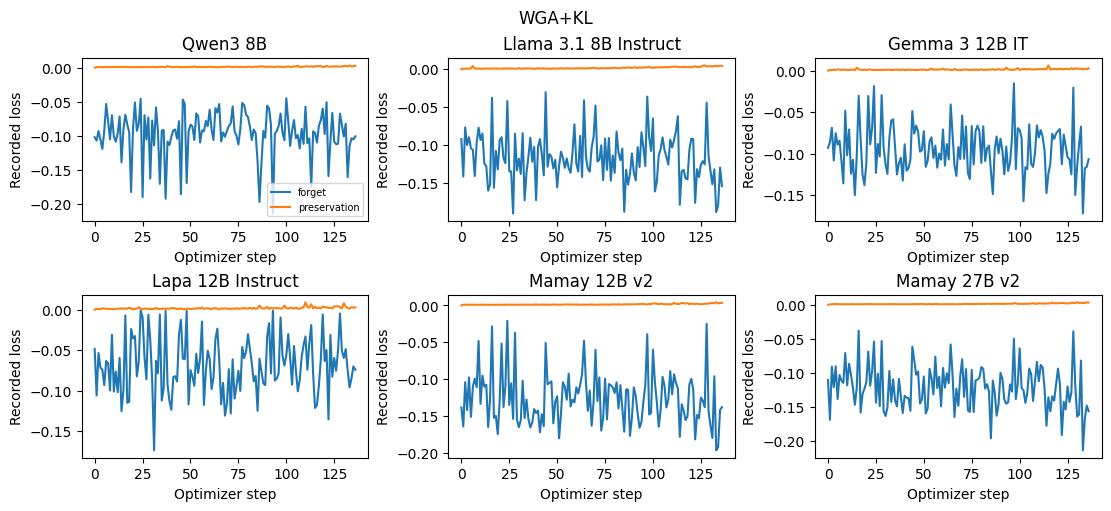

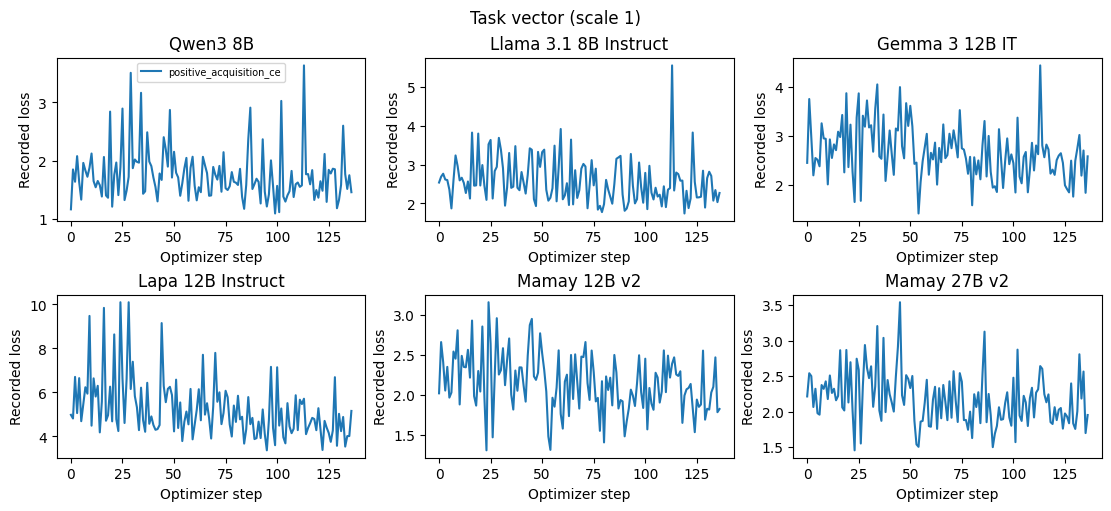

In [6]:
import matplotlib.pyplot as plt

for method, report in reports.items():
    figure, axes = plt.subplots(2, 3, figsize=(11, 5), constrained_layout=True)
    for axis, (model, history) in zip(axes.flat, report["training_history"].items(), strict=True):
        data = pd.DataFrame(history)
        columns = ["forget", "preservation"] if method == "wga_kl" else ["positive_acquisition_ce"]
        for column in columns:
            axis.plot(data["step"], data[column], label=column)
        axis.set(title=model, xlabel="Optimizer step", ylabel="Recorded loss")
    axes.flat[0].legend(fontsize=7)
    figure.suptitle(labels[method])
    plt.show()

## Implementation and interpretation

The [objectives](../src/fairforget/unlearning/objectives.py) and
[trainer](../src/fairforget/unlearning/trainer.py) implement WGA and positive acquisition.
The pinned [scale-one application](https://github.com/reirei-00/fair_forget/blob/ab233fdd1c72d8e0c838a04e1fc5b851db3b3ad6/src/fairforget/unlearning/task_vector_apply.py)
verifies the acquisition and applies the fixed vector.

This is a one-seed application experiment. Profile variants share semantic components.
The retain bank measures in-domain preservation; it does not establish broad capability
retention. Use the paired evaluation to assess effects for each model and language.